# Pronóstico del precio de bolsa a una semana: SARIMAX y XGBoost

Este notebook reúne la metodología y los resultados de los dos modelos: objetivo, datos, elección
de variables, ajuste de cada modelo, criterio de comparación y resultados en la prueba.

No se entrena ningún modelo aquí. XGBoost se entrenó en `4_modelo_xgboost.ipynb` (Python) y SARIMAX
en `5_modelo_sarimax.ipynb` (R). Este notebook lee los pronósticos guardados en `resultados/` y los
compara.

**Contenido**

1. Objetivo
2. Datos
3. Diseño de la evaluación
4. XGBoost
5. SARIMAX
6. Criterio de comparación
7. Resultados
8. Conclusiones

## 1. Objetivo

Pronosticar el precio de bolsa de cada hora de la semana siguiente. XM publica el precio con
atraso: si el día actual es $R$, el último precio conocido es el de $t = R - 2$. Con información
hasta $t$, el día siguiente corresponde a $h = 3$ y la semana completa va de $h = 3$ a $h = 9$,
es decir, 7 días por 24 horas, 168 precios.

Ambos modelos pronostican el cambio en logaritmo frente al último precio conocido a la misma hora
$H$:

$$y_h = \ln P(t+h,\,H) - \ln P(t,\,H)$$

Se trabaja en logaritmos porque el precio tiene picos muy altos y en logaritmos los cambios se
interpretan como porcentajes. El pronóstico en pesos es $\hat P(t+h,H) = P(t,H)\,e^{\hat y_h}$.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

COLOR = {"real": "#2a78d6", "XGBoost": "#eb6834", "SARIMAX": "#1baf7a",
         "ingenuo del día": "#898781", "ingenuo semanal": "#c3c2b7"}
HS = range(3, 10)
XGB = Path("resultados/modelo_xgboost")
SAR = Path("resultados/modelo_sarimax")

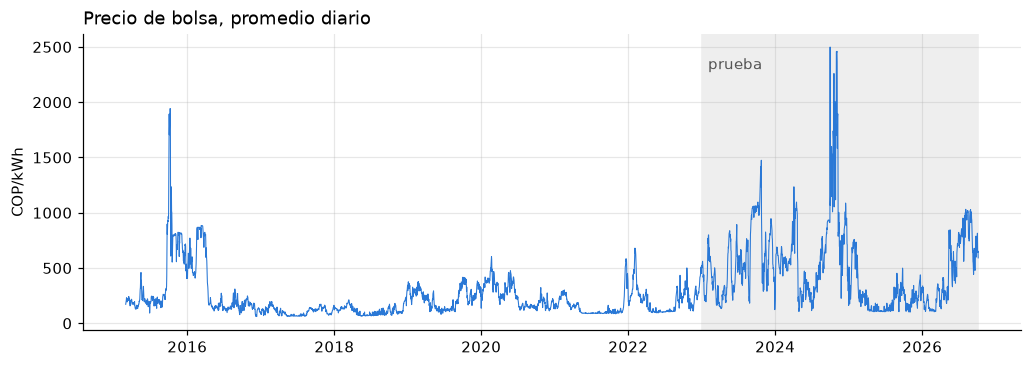

101,712 horas, del 2015-03-01 al 2026-10-06


In [2]:
panel = pd.read_csv("paneles/panel_horario_modelo.csv.gz", usecols=["fecha", "hora", "precio"],
                    parse_dates=["fecha"])
diario = panel.groupby("fecha")["precio"].mean()

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(diario.index, diario, color=COLOR["real"], lw=0.7)
ax.axvspan(pd.Timestamp("2023-01-01"), diario.index[-1], color="#eeeeee", zorder=0)
ax.text(pd.Timestamp("2023-02-01"), diario.max() * 0.92, "prueba", color="#555555")
ax.set_ylabel("COP/kWh")
ax.set_title("Precio de bolsa, promedio diario", loc="left")
plt.show()

print(f"{len(panel):,} horas, del {panel.fecha.min().date()} al {panel.fecha.max().date()}")

Se observan los picos de finales de 2015 (El Niño), de 2023 y de septiembre-octubre de 2024. El
precio cambia de nivel con frecuencia, lo que dificulta pronosticarlo con más de unos días de
anticipación. La zona gris es el periodo de prueba, que no se usó para entrenar ni para tomar
ninguna decisión.

## 2. Datos

### 2.1 Fuentes

Todas las fuentes son públicas. La descarga está en `1_descargar.py` y `1b_ideam.py`.

| Fuente | Variables |
|---|---|
| XM (API de XM y SIMEM) | precio, demanda y su pronóstico, generación por planta, embalses, aportes hídricos, ofertas y disponibilidad de las plantas, despacho programado y costo marginal |
| IDEAM | lluvia por cuenca |
| NOAA | índice ONI de El Niño |
| Banco de la República | TRM |

### 2.2 Construcción y limpieza del panel

El panel tiene una fila por día y hora, del 1 de marzo de 2015 al 6 de octubre de 2026 (pasos
`2_construir_panel.py`, `2b_panel_horario.py` y `2c_caracteristicas_horarias.py`). Se corrigieron
tres problemas de la información publicada:

- **Desfase horario de SIMEM.** La hora de SIMEM empieza una hora antes que la de XM (la hora 04:00
  de SIMEM es la hora 5 de XM). La corrección se verificó con 240 horas de costo marginal, que
  coinciden en su totalidad.
- **Mercado duplicado.** En 70 días de 2019, 2020 y 2024 SIMEM incluye un mercado que corresponde
  al total nacional, lo que duplicaba el pronóstico de demanda. Se excluyó.
- **Demanda incompleta.** El 5 y el 6 de octubre de 2026 la demanda se publicó incompleta (22% de
  lo normal). Esos días quedan con la demanda como dato faltante.

### 2.3 Disponibilidad de la información

Cada variable entra solo desde el día en que se publica. El precio llega con dos días de atraso y
algunas variables llegan más tarde; por ejemplo, la curva de ofertas se publica con 8 días
adicionales. Usar un dato antes de su publicación haría que los resultados parecieran mejores de
lo que son en la práctica.

### 2.4 Variables candidatas

A partir de 134 variables base se construyeron rezagos, medias móviles, tendencias y medidas de
variabilidad, para un total de 1.861 columnas candidatas.

## 3. Diseño de la evaluación

### 3.1 Periodos

| Periodo | Uso |
|---|---|
| 2015-2019 | elección de variables y órdenes |
| 2020-2022 | validación: número de variables, hiperparámetros y versión final de cada modelo |
| 2023-2025 | prueba |
| 2026 (hasta el 6 de octubre) | segunda prueba |

La prueba se corrió una sola vez, con la configuración de cada modelo ya congelada. En la prueba,
ambos modelos se reentrenan el primer día de cada mes con toda la información anterior.

### 3.2 Modelos de referencia

Un modelo se considera útil solo si supera a una regla sencilla. Se usan dos pronósticos
ingenuos:

- **Ingenuo del día:** repite el último precio conocido a la misma hora, $P(t, H)$, lo que equivale
  a $\hat y = 0$. No corresponde al precio del día anterior: por el atraso, en $h = 3$ es el precio
  de tres días antes y en $h = 9$ el de nueve días antes.
- **Ingenuo semanal:** repite el precio de esa hora en el mismo día de la semana de la última semana
  conocida. Recoge el patrón semanal; por ejemplo, el precio de los domingos es más bajo.

Cada modelo se compara contra el mejor de los dos. A continuación se cargan los pronósticos de la
prueba.

In [3]:
xgb = pd.concat([pd.read_csv(XGB / f"prueba_h{h}.csv.gz").assign(periodo="2023-2025") for h in HS]
                + [pd.read_csv(XGB / "prueba2026_mensual.csv.gz").query("3 <= h <= 9").assign(periodo="2026")])
sar = pd.concat([pd.read_csv(SAR / "prueba_2023_2025.csv.gz"), pd.read_csv(SAR / "prueba_2026.csv.gz")])

d = xgb.merge(sar[["fecha", "hora", "h", "lp_hat"]], on=["fecha", "hora", "h"], validate="one_to_one")
assert len(d) == len(xgb) == len(sar)

d["fecha"] = pd.to_datetime(d["fecha"])
d["objetivo"] = d["fecha"] + pd.to_timedelta(d["h"], unit="D")
d["año"] = d["fecha"].dt.year

# errores en logaritmo (real menos pronóstico); el ingenuo del día pronostica y = 0
d["e_XGBoost"] = d["y"] - d["y_hat"]
d["e_SARIMAX"] = d["y"] - (d["lp_hat"] - np.log(d["precio_t"]))
d["e_ingenuo del día"] = d["y"]
d["e_ingenuo semanal"] = d["y"] - d["y_semanal"]

MODELOS = ["XGBoost", "SARIMAX", "ingenuo del día", "ingenuo semanal"]
print(f"{len(d):,} pronósticos en las mismas filas para los dos modelos")
d.groupby("periodo").agg(filas=("y", "size"), desde=("objetivo", "min"), hasta=("objetivo", "max"))

228,984 pronósticos en las mismas filas para los dos modelos


,filas,desde,hasta
periodo,,,
2023-2025,183120,2023-01-04,2025-12-31
2026,45864,2026-01-04,2026-10-06


In [4]:
def rmse(e):
    return np.sqrt(np.mean(e ** 2))


ingenuos = pd.DataFrame({m: d[d.periodo == "2023-2025"].groupby("h")[f"e_{m}"].apply(rmse)
                         for m in ["ingenuo del día", "ingenuo semanal"]})
ingenuos["el mejor"] = ingenuos.idxmin(axis=1)
print("RMSE en logaritmo de cada ingenuo, 2023-2025")
ingenuos

RMSE en logaritmo de cada ingenuo, 2023-2025


,ingenuo del día,ingenuo semanal,el mejor
h,,,
3,0.411,0.516,ingenuo del día
4,0.447,0.516,ingenuo del día
5,0.479,0.516,ingenuo del día
6,0.499,0.516,ingenuo del día
7,0.517,0.517,ingenuo del día
8,0.555,0.639,ingenuo del día
9,0.584,0.640,ingenuo del día


El ingenuo del día es el mejor en todos los horizontes. En $h = 7$ ambos coinciden porque toman
exactamente el mismo día. En $h = 8$ y $9$ el semanal debe ir dos semanas atrás y su error aumenta.
En este mercado pesa más la persistencia del nivel reciente del precio que el patrón del día de la
semana. Por eso todas las mejoras que siguen se miden frente al ingenuo del día.

## 4. XGBoost

### 4.1 Especificación

XGBoost es un conjunto de árboles de decisión entrenados en secuencia: cada árbol nuevo corrige
los errores que dejan los anteriores (*gradient boosting*; Chen y Guestrin, 2016). La predicción es
la suma de los árboles:

$$\hat y = \sum_{k=1}^{K} f_k(x)$$

Se estima un modelo directo por horizonte, de $h = 3$ a $h = 7$. Los horizontes 8 y 9 usan la
configuración de $h = 7$, porque cuando se ajustó el modelo el alcance era de 30 días y esos dos
horizontes no tuvieron validación propia.

### 4.2 Elección de variables

La elección se hace por separado para cada horizonte (`2d_seleccion_variables.py`), en tres pasos
con datos distintos:

1. **Limpieza (2015-2019).** Se eliminan las columnas casi constantes, las inestables (más de 25%
   de sus valores de 2018-2019 fuera del rango de 2015-2017, porque un árbol no extrapola) y los
   niveles que solo siguen a la tasa de cambio. De cada grupo de columnas con correlación de
   Spearman mayor a 0,95 se conserva una.
2. **Orden (2015-2019).** Se entrena un XGBoost con configuración fija dos veces: con 2015-2017,
   evaluado en 2018, y con 2015-2018, evaluado en 2019. Se agregan 10 columnas de ruido, copias de
   columnas reales con los días barajados. La importancia de cada columna es su valor SHAP absoluto
   promedio en el año no visto. Continúan solo las columnas que superan al mejor ruido en los dos
   años.
3. **Número de columnas (2020-2022).** Se entrena con 2015-2019 usando las primeras 10, 20, 40, 80
   y 160 columnas del orden. Se elige el número más pequeño cuyo error no supera al mejor en más de
   un error estándar.

In [5]:
col = pd.read_csv("paneles/panel_horario_modelo_columnas.csv")
pasos = []
for h in range(3, 8):
    pasos.append({"h": h,
                  "candidatas": (col["tipo"] != "fija").sum(),
                  "tras la limpieza": (col[f"limpieza_h{h}"] == "pasa").sum(),
                  "superan al ruido": col[f"orden_h{h}"].notna().sum(),
                  "entran": ((col[f"entra_h{h}"] == True) & (col["tipo"] != "fija")).sum()})
pd.DataFrame(pasos).set_index("h")

,candidatas,tras la limpieza,superan al ruido,entran
h,,,,
3,1861,1289,15,10
4,1861,1290,43,20
5,1861,1291,89,10
6,1861,1290,99,10
7,1861,1289,117,20


Además de estas columnas, todos los modelos incluyen el precio del día $t$ (`lp`) y variables de
calendario: hora, día de la semana, mes, festivo y día de la semana del día pronosticado.

Columnas elegidas para $h = 3$, ordenadas por importancia:

In [6]:
que_es = {
    "dlp_ma30d_mh": "precio de hoy frente a su media de 30 días a esa hora",
    "dlp_dia": "precio de esa hora frente a la media del día",
    "dlp_ma7d_mh": "precio de hoy frente a su media de 7 días a esa hora",
    "margen_ofertado_l3d": "capacidad ofertada sobre demanda, hace 3 días",
    "dlp_ultima": "precio de esa hora frente al de la última hora del día",
    "dlp_max_24h": "distancia del precio al máximo de las últimas 24 horas",
    "dlp_max_7d": "distancia del precio al máximo de 7 días a esa hora",
    "aportes_pct_sistema_delta_7d": "cambio semanal de los aportes hídricos",
    "presion_hidro_horaria_ultima": "demanda por cada MWh de aportes hídricos",
    "aportes_pct_sistema_l0d": "aportes hídricos en % de la media histórica",
}
h3 = (col[(col["entra_h3"] == True) & (col["tipo"] != "fija")]
      .sort_values("importancia_h3", ascending=False)[["columna", "variable"]])
h3["qué mide"] = h3["columna"].map(que_es)
h3.reset_index(drop=True)

,columna,variable,qué mide
0,dlp_ma30d_mh,lp,precio de hoy frente a su media de 30 días a e...
1,dlp_dia,lp,precio de esa hora frente a la media del día
2,dlp_ma7d_mh,lp,precio de hoy frente a su media de 7 días a es...
3,margen_ofertado_l3d,margen_ofertado,"capacidad ofertada sobre demanda, hace 3 días"
4,dlp_ultima,lp,precio de esa hora frente al de la última hora...
5,dlp_max_24h,lp,distancia del precio al máximo de las últimas ...
6,dlp_max_7d,lp,distancia del precio al máximo de 7 días a esa...
7,aportes_pct_sistema_delta_7d,aportes_pct_sistema,cambio semanal de los aportes hídricos
8,presion_hidro_horaria_ultima,presion_hidro_horaria,demanda por cada MWh de aportes hídricos
9,aportes_pct_sistema_l0d,aportes_pct_sistema,aportes hídricos en % de la media histórica


In [7]:
grupos = {}
for h in range(3, 8):
    e = col[(col[f"entra_h{h}"] == True) & (col["tipo"] != "fija")]
    grupos[f"h = {h}"] = e["tipo"].replace({"precio": "del precio", "horaria": "horarias",
                                            "diaria": "diarias"}).value_counts()
pd.DataFrame(grupos).fillna(0).astype(int)

,h = 3,h = 4,h = 5,h = 6,h = 7
tipo,,,,,
del precio,6,9,6,7,9
diarias,2,7,1,0,6
horarias,2,4,3,3,5


El precio pasado domina en todos los horizontes, en especial su distancia a las medias recientes:
el precio tiende a volver a su nivel. Le siguen el margen de oferta y los aportes hídricos. En
$h = 4$ y $h = 7$ entran 20 columnas, con más variables de hidrología y de generación térmica.

### 4.3 Hiperparámetros

Se eligieron en tres etapas, todas con 2020-2022:

1. **Búsqueda al azar.** 30 combinaciones en tres pliegues anuales: entrenamiento con todo lo
   anterior y evaluación en 2020, 2021 y 2022.
2. **Walk-forward mensual.** Las 3 mejores combinaciones se reevalúan reentrenando el primer día de
   cada mes. Se elige la más simple de las que están a un error estándar de la mejor.
3. **Variantes.** Pérdida Pseudo-Huber, entrenamiento solo con los últimos tres años y corrección
   de sesgo. Una variante entraba solo si reducía el error en más de un error estándar; ninguna lo
   hizo.

In [8]:
cfg = json.load(open(XGB / "configuracion_final.json", encoding="utf-8"))
pd.DataFrame({f"h = {h}": cfg[str(h)]["parametros"] for h in range(3, 8)}).T

,max_depth,min_child_weight,n_estimators,subsample,colsample_bytree,reg_lambda
h = 3,4.0,50.0,200.0,0.75,0.82,8.39
h = 4,5.0,240.0,200.0,0.71,0.79,1.50
h = 5,3.0,50.0,300.0,0.72,0.75,8.46
h = 6,4.0,240.0,200.0,0.88,0.74,5.36
h = 7,6.0,50.0,100.0,0.74,0.54,3.80


La regularización del modelo está en estos hiperparámetros: `max_depth` limita la profundidad de
cada árbol; `min_child_weight` fija el mínimo de horas por hoja (240 horas equivalen a 10 días);
`subsample` y `colsample_bytree` son la fracción de filas y de columnas que ve cada árbol; y
`reg_lambda` penaliza los valores grandes de las hojas (L2). La tasa de aprendizaje es fija, 0,03.
La regla de un error estándar también favorece los modelos más simples.

Como 2020-2022 se usó tanto para el número de variables como para los hiperparámetros, el error de
validación es optimista. La medida que cuenta es la prueba.

## 5. SARIMAX

### 5.1 Especificación

SARIMAX es un modelo lineal de series de tiempo (Box et al., 2015; Hyndman y Athanasopoulos, 2021).
Explica el precio con sus valores pasados, sus errores pasados, un ciclo estacional y, si aportan,
variables exógenas. Se estiman 24 modelos, uno por hora del día, cada uno con la serie diaria del
logaritmo del precio de esa hora y estacionalidad semanal ($s = 7$). Es una regresión con errores
SARIMA: el festivo entra en la regresión y el error $\eta_t$ sigue el modelo SARIMA.

$$\ln P_t = \beta\,\text{festivo}_t + \eta_t, \qquad \phi(B)\,\Phi(B^7)\,(1-B)^d\,(1-B^7)^D\,\eta_t = \theta(B)\,\Theta(B^7)\,\varepsilon_t$$

donde $B$ es el operador de rezago ($B\,x_t = x_{t-1}$). La estimación se hizo en R con el paquete
`forecast`. Todas las decisiones se tomaron con datos hasta 2022 y con reglas fijadas de antemano,
sin usar los resultados de XGBoost.

### 5.2 Elección de los órdenes (2015-2019)

La prueba KPSS indicó una diferencia regular ($d = 1$) y la prueba OCSB ninguna diferencia
estacional ($D = 0$) en las 24 horas. Los órdenes $p$, $q$, $P$ y $Q$ se eligieron con el AICc
mediante `auto.arima`.

In [9]:
ordenes = pd.read_csv(SAR / "etapa2_ordenes.csv")
ordenes["orden"] = [f"({r.p},{r.d},{r.q})({r.P},{r.D},{r.Q})" for r in ordenes.itertuples()]
print(f"{ordenes['orden'].nunique()} órdenes distintos en las 24 horas")
ordenes["orden"].value_counts().head(5).rename("horas")

12 órdenes distintos en las 24 horas


orden
(1,1,2)(0,0,2)    5
(1,1,2)(0,0,1)    3
(2,1,1)(0,0,2)    3
(1,1,1)(0,0,0)    3
(1,1,3)(0,0,2)    3
Name: horas, dtype: int64

### 5.3 Elección de variables exógenas (2015-2019)

Las candidatas son las variables base que pasan la misma limpieza usada en XGBoost. Cada una entra
con 9 días de rezago, $x(t+h-9)$, para que esté disponible en cualquier horizonte de la semana. Se
aplican tres filtros seguidos:

1. **Preblanqueo (Box y Jenkins).** Se filtran el precio y la variable con el ARIMA de cada hora y
   se mide la correlación cruzada de los residuos en el rezago 9. Pasa la variable significativa al
   5%, con corrección de Bonferroni por el número de candidatas, en al menos 12 de las 24 horas.
2. **Selección hacia adelante** con el AICc sumado en las 24 horas, hasta 6 variables.
3. **Prueba t** de los coeficientes: se conserva la variable con $p < 0{,}05$ en al menos 12 horas.

In [10]:
cand = pd.read_csv(SAR / "etapa3_candidatas.csv")
print(f"Variables base: {len(cand)}")
print(cand["motivo"].value_counts().to_string())
print(f"\nPasan el preblanqueo: {cand['pasa'].sum()} ({', '.join(cand.loc[cand['pasa'], 'variable'])})")
print(pd.read_csv(SAR / "etapa3_adelante.csv").to_string(index=False))

Variables base: 133
motivo
candidata                   122
inestable                     8
nivel que sigue al dólar      2
casi constante                1

Pasan el preblanqueo: 1 (holgura_rel)
 paso          variable  aicc_total
    0 (solo calendario)  -23215.255
    1       holgura_rel  -23462.131


Solo `holgura_rel`, la holgura de capacidad frente a la demanda, pasa los tres filtros: es
significativa en 12 horas en el preblanqueo, reduce el AICc de −23.215 a −23.462 y su coeficiente
tiene $p < 0{,}05$ en 17 de 24 horas.

### 5.4 Validación y modelo final (2020-2022)

Se comparan tres versiones en $h = 3$ a $9$. Una versión más compleja entra solo si supera a la
anterior con Diebold-Mariano $p < 0{,}05$.

In [11]:
val = pd.read_csv(SAR / "etapa4_comparacion.csv")
val["version"] = val["version"].map({"comun": "un solo orden para las 24 horas",
                                     "por_hora": "un orden distinto por hora",
                                     "exogenas": "un solo orden + holgura_rel"})
val["mejora vs ingenuo del día (%)"] = 100 * (1 - val["rmse_log"] / val["rmse_ingenuo_dia"])
val[["version", "rmse_log", "mejora vs ingenuo del día (%)", "dm_p_contra_anterior"]]

,version,rmse_log,mejora vs ingenuo del día (%),dm_p_contra_anterior
0,un solo orden para las 24 horas,0.281,4.678,NaN
1,un orden distinto por hora,0.281,4.659,0.865
2,un solo orden + holgura_rel,0.281,4.672,0.969


Ni el orden por hora ($p = 0{,}87$) ni la variable exógena ($p = 0{,}97$) mejoran el pronóstico
fuera de la muestra. Las pruebas de 2015-2019 miden ajuste dentro de la muestra y a un paso; la
validación mide el pronóstico de una semana con datos nuevos, y por eso es la que decide. El modelo
final es el más sencillo:

In [12]:
sar_cfg = json.load(open(SAR / "configuracion_final.json", encoding="utf-8"))
o = sar_cfg["ordenes"][0]
print(f"SARIMAX({o['p']},{o['d']},{o['q']})({o['P']},{o['D']},{o['Q']})_7 en las 24 horas, "
      f"con festivo y sin variables exógenas: {sar_cfg['exogenas']}")

SARIMAX(1,1,2)(0,0,2)_7 en las 24 horas, con festivo y sin variables exógenas: []


Para cada hora $H$:

$$\ln P_t = \beta\,\text{festivo}_t + \eta_t, \qquad (1-\phi_1 B)(1-B)\,\eta_t = (1+\theta_1 B+\theta_2 B^2)(1+\Theta_1 B^7+\Theta_2 B^{14})\,\varepsilon_t$$

En la prueba, los coeficientes se reestiman el primer día de cada mes con toda la información
anterior. Dentro del mes solo se actualiza el estado del modelo con los precios nuevos.

## 6. Criterio de comparación

- **Mismas filas.** Ambos modelos se evalúan en los mismos días, horas y horizontes, con los mismos
  ingenuos (verificado al cargar los datos).
- **Criterio.** Un modelo funciona si su RMSE en logaritmo es al menos 5% menor que el del mejor
  ingenuo y si la prueba de Diebold-Mariano contra ese ingenuo da $p < 0{,}05$. Diebold-Mariano
  indica si la diferencia puede atribuirse al azar; como los errores de días consecutivos están
  correlacionados, se usa la varianza de Newey-West. El umbral de 5% es una decisión del autor.

$$\text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n} (y_i - \hat y_i)^2}
\qquad
\text{mejora} = 100\left(1 - \frac{\text{RMSE}_{\text{modelo}}}{\text{RMSE}_{\text{ingenuo}}}\right)$$

- **Medidas adicionales.** Mejora por horizonte y por año, Diebold-Mariano entre los dos modelos,
  error en pesos (MAE, RMSE, MAPE y sesgo) y descomposición del error en nivel y forma del día.

El alcance de una semana se definió después de observar la prueba de XGBoost en 2026, donde el
modelo dejaba de superar al ingenuo más allá de $h = 7$. Para SARIMAX el criterio quedó fijado
antes de correr su prueba.

## 7. Resultados

### 7.1 Semana completa (h = 3 a 9)

In [13]:
def tabla_semana(g):
    fila = {m: rmse(g[f"e_{m}"]) for m in MODELOS}
    for m in ["XGBoost", "SARIMAX"]:
        fila[f"mejora {m} (%)"] = 100 * (1 - fila[m] / fila["ingenuo del día"])
    return pd.Series(fila)


semana = d.groupby("periodo").apply(tabla_semana, include_groups=False)
semana

,XGBoost,SARIMAX,ingenuo del día,ingenuo semanal,mejora XGBoost (%),mejora SARIMAX (%)
periodo,,,,,,
2023-2025,0.443,0.470,0.502,0.554,11.638,6.409
2026,0.392,0.411,0.435,0.491,9.962,5.590


In [14]:
crit_x = pd.read_csv(XGB / "alcance_semana.csv").set_index("periodo")
crit_s = pd.read_csv(SAR / "prueba_criterio.csv").query("bloque == 'h = 3 a 9'").set_index("periodo")

veredicto = pd.DataFrame({
    "mejora XGBoost (%)": crit_x["mejora"], "p XGBoost": crit_x["dm_p"],
    "mejora SARIMAX (%)": crit_s["mejora"], "p SARIMAX": crit_s["dm_p"]}).loc[["2023-2025", "2026"]]
veredicto["XGBoost funciona"] = (veredicto["mejora XGBoost (%)"] >= 5) & (veredicto["p XGBoost"] < 0.05)
veredicto["SARIMAX funciona"] = (veredicto["mejora SARIMAX (%)"] >= 5) & (veredicto["p SARIMAX"] < 0.05)
for c in ["p XGBoost", "p SARIMAX"]:
    veredicto[c] = veredicto[c].map(lambda p: "< 0,001" if p < 0.001 else f"{p:.3f}")
veredicto.round(1)

,mejora XGBoost (%),p XGBoost,mejora SARIMAX (%),p SARIMAX,XGBoost funciona,SARIMAX funciona
periodo,,,,,,
2023-2025,11.6,"< 0,001",6.4,"< 0,001",True,True
2026,10.0,0.001,5.6,"< 0,001",True,True


Las mejoras calculadas con los pronósticos coinciden con las de cada notebook. Los valores $p$ de
Diebold-Mariano se toman de los resultados de `4_modelo_xgboost.ipynb` y `5_modelo_sarimax.ipynb`,
donde se hace el cálculo.

Ambos modelos cumplen el criterio en los dos periodos. XGBoost obtiene una mejora mayor: 11,6%
frente a 6,4% en 2023-2025, y 10,0% frente a 5,6% en 2026.

### 7.2 Por horizonte

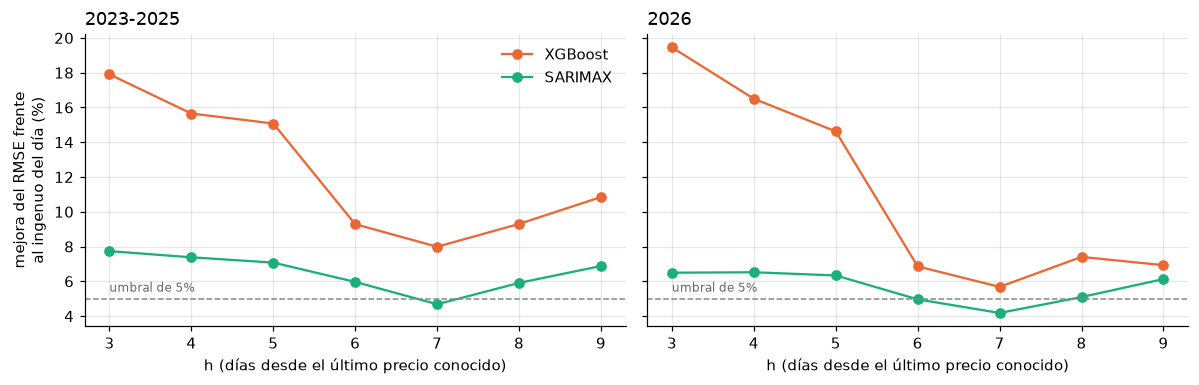

XGBoost         SARIMAX     
periodo 2023-2025  2026 2023-2025 2026
h                                     
3            17.9  19.5       7.7  6.5
4            15.7  16.5       7.4  6.5
5            15.1  14.6       7.1  6.3
6             9.3   6.9       6.0  5.0
7             8.0   5.7       4.7  4.2
8             9.3   7.4       5.9  5.1
9            10.8   6.9       6.9  6.1

In [15]:
por_h = (d.groupby(["periodo", "h"])
          .apply(lambda g: pd.Series({m: 100 * (1 - rmse(g[f"e_{m}"]) / rmse(g["e_ingenuo del día"]))
                                      for m in ["XGBoost", "SARIMAX"]}), include_groups=False))

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, p in zip(ejes, ["2023-2025", "2026"]):
    for m in ["XGBoost", "SARIMAX"]:
        ax.plot(list(HS), por_h.loc[p, m], marker="o", color=COLOR[m], label=m)
    ax.axhline(5, color="#888888", ls="--", lw=1)
    ax.text(3, 5.4, "umbral de 5%", color="#666666", fontsize=8)
    ax.set_title(p, loc="left")
    ax.set_xlabel("h (días desde el último precio conocido)")
ejes[0].set_ylabel("mejora del RMSE frente\nal ingenuo del día (%)")
ejes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

por_h.unstack("periodo").round(1)

La ventaja de XGBoost se concentra en los primeros días: 18% frente a 8% en $h = 3$, unos 10 puntos
de diferencia. Desde $h = 6$ la distancia baja a entre 1 y 4 puntos. SARIMAX es más estable, con
mejoras de entre 4% y 8% en todos los horizontes. En los primeros días XGBoost aprovecha variables
como el margen de oferta o los aportes hídricos, cuya relación con el precio se debilita a medida
que el horizonte se aleja.

### 7.3 Por año y comparación directa

El año corresponde al día en que se hace el pronóstico.

In [16]:
por_año = d[d.periodo == "2023-2025"].groupby("año").apply(tabla_semana, include_groups=False)
comp = pd.read_csv(SAR / "comparacion_xgboost.csv").set_index("periodo")
por_año["p XGBoost vs SARIMAX"] = comp.loc[["2023", "2024", "2025"], "dm_p_sar_vs_xgb"].to_numpy()
por_año[["XGBoost", "SARIMAX", "ingenuo del día", "mejora XGBoost (%)", "mejora SARIMAX (%)",
         "p XGBoost vs SARIMAX"]]

,XGBoost,SARIMAX,ingenuo del día,mejora XGBoost (%),mejora SARIMAX (%),p XGBoost vs SARIMAX
año,,,,,,
2023,0.474,0.521,0.544,12.861,4.162,0.003
2024,0.470,0.478,0.508,7.642,6.061,0.707
2025,0.379,0.401,0.447,15.266,10.370,0.070


XGBoost tiene menor error en todos los años, pero en la comparación directa con Diebold-Mariano la
diferencia solo es significativa en 2023 ($p = 0{,}003$) y en 2023-2025 en conjunto
($p = 0{,}011$). En 2024 no se distinguen ($p = 0{,}71$), y en 2026 la diferencia tampoco alcanza
0,05 ($p = 0{,}06$).

### 7.4 Error en pesos

El criterio se mide en logaritmos, pero el precio se usa en pesos. En COP/kWh la ventaja de XGBoost
se reduce.

In [17]:
d["real"] = d["precio_t"] * np.exp(d["y"])
pesos = {"XGBoost": d["precio_t"] * np.exp(d["y_hat"]), "SARIMAX": np.exp(d["lp_hat"]),
         "ingenuo del día": d["precio_t"]}

filas = []
for p in ["2023-2025", "2026"]:
    s = d["periodo"] == p
    for m, pron in pesos.items():
        e = pron[s] - d.loc[s, "real"]
        filas.append({"periodo": p, "modelo": m, "MAE": e.abs().mean(), "RMSE": rmse(e),
                      "MAPE (%)": 100 * (e.abs() / d.loc[s, "real"]).mean(), "sesgo (pron − real)": e.mean()})
pd.DataFrame(filas).set_index(["periodo", "modelo"]).round(1)

MAE   RMSE  MAPE (%)  sesgo (pron − real)
periodo   modelo                                                      
2023-2025 XGBoost          148.6  247.5      36.2                -46.4
          SARIMAX          148.8  242.1      39.0                -15.3
          ingenuo del día  150.1  257.1      40.1                  1.3
2026      XGBoost          122.5  175.7      29.5                -38.0
          SARIMAX          122.9  176.5      30.4                -29.2
          ingenuo del día  127.1  188.5      32.4                 -8.3

En 2023-2025 el RMSE en pesos de SARIMAX (242) es menor que el de XGBoost (247), y XGBoost queda en
promedio 46 COP/kWh por debajo del precio real. Hay dos razones. Primero, ambos modelos minimizan
el error en logaritmos, y al volver a pesos con $e^{\hat y}$ el pronóstico se acerca a la mediana y
no a la media, por lo que tiende a quedarse corto. Segundo, en pesos pesan más los errores de los
meses de precios altos. En MAPE, XGBoost sigue siendo el mejor (36% frente a 39%).

### 7.5 Nivel y forma del día

El error de cada día se separa en dos partes: el nivel (error en el promedio de las 24 horas) y la
forma (error en la distribución del precio entre las horas).

In [18]:
nf = comp.loc[["2023-2025", "2026"]]
nivel_forma = pd.DataFrame({
    ("nivel", "XGBoost"): nf["nivel_xgboost"], ("nivel", "SARIMAX"): nf["nivel_sarimax"],
    ("nivel", "ingenuo"): nf["nivel_ing_dia"],
    ("forma", "XGBoost"): nf["forma_xgboost"], ("forma", "SARIMAX"): nf["forma_sarimax"],
    ("forma", "ingenuo"): nf["forma_ing_dia"]})
nivel_forma.round(3)

nivel                   forma                
          XGBoost SARIMAX ingenuo XGBoost SARIMAX ingenuo
periodo                                                  
2023-2025   0.385   0.402   0.415   0.221   0.243   0.282
2026        0.341   0.356   0.363   0.193   0.205   0.240

Ninguno de los dos modelos mejora mucho el nivel del día: en 2023-2025 el ingenuo tiene 0,415,
SARIMAX 0,402 y XGBoost 0,385. La mejora está en la forma, sobre todo en XGBoost (0,221 frente a
0,282). Que dos modelos tan distintos fallen en lo mismo sugiere que el límite está en la
información disponible y no en el modelo.

### 7.6 Semana de ejemplo

Pronóstico con datos hasta el 6 de octubre de 2026 para la semana del 9 al 15 de octubre. Los
pronósticos se guardaron antes de descargar el precio real.

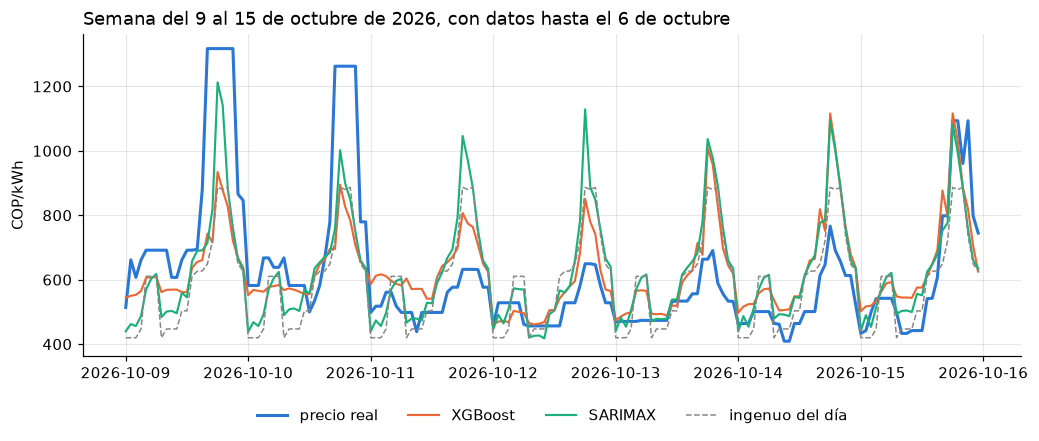

{'XGBoost': np.float64(0.201), 'SARIMAX': np.float64(0.218), 'ingenuo del día': np.float64(0.234)}


In [19]:
real = pd.read_csv(XGB / "precio_real_final.csv", parse_dates=["fecha_objetivo"])
px = pd.read_csv(XGB / "pronostico_final.csv", parse_dates=["fecha_objetivo"])
ps = pd.read_csv(SAR / "pronostico_final.csv", parse_dates=["fecha"])
ps["fecha_objetivo"] = ps["fecha"] + pd.to_timedelta(ps["h"], unit="D")
ps["SARIMAX"] = np.exp(ps["lp_hat"])

sem = (px[["fecha_objetivo", "hora", "precio_pron", "precio_t"]]
       .merge(real, on=["fecha_objetivo", "hora"])
       .merge(ps[["fecha_objetivo", "hora", "SARIMAX"]], on=["fecha_objetivo", "hora"])
       .rename(columns={"precio_pron": "XGBoost", "precio_t": "ingenuo del día"})
       .sort_values(["fecha_objetivo", "hora"]))
sem["momento"] = sem["fecha_objetivo"] + pd.to_timedelta(sem["hora"] - 1, unit="h")

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(sem["momento"], sem["precio_real"], color=COLOR["real"], lw=2, label="precio real")
for m in ["XGBoost", "SARIMAX"]:
    ax.plot(sem["momento"], sem[m], color=COLOR[m], lw=1.4, label=m)
ax.plot(sem["momento"], sem["ingenuo del día"], color=COLOR["ingenuo del día"], lw=1, ls="--",
        label="ingenuo del día")
ax.set_ylabel("COP/kWh")
ax.set_title("Semana del 9 al 15 de octubre de 2026, con datos hasta el 6 de octubre", loc="left")
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.show()

print({m: round(rmse(np.log(sem["precio_real"]) - np.log(sem[m])), 3)
       for m in ["XGBoost", "SARIMAX", "ingenuo del día"]})

En esta semana el RMSE en logaritmo fue 0,201 para XGBoost, 0,218 para SARIMAX y 0,234 para el
ingenuo. Es una sola semana, más tranquila que lo habitual, y sirve para ilustrar el comportamiento
de los modelos, no para evaluarlos.

## 8. Conclusiones

1. Ambos modelos superan al ingenuo del día en la semana completa, en 2023-2025 y en 2026, y
   cumplen el criterio del 5% con Diebold-Mariano.
2. XGBoost es mejor en logaritmos (11,6% frente a 6,4% en 2023-2025), con la ventaja concentrada en
   los primeros días de la semana. Desde $h = 6$ la distancia entre los dos se reduce.
3. En la comparación directa, la diferencia entre los dos solo es significativa en 2023 y en
   2023-2025 en conjunto. En 2024 y 2026 no se distinguen.
4. En pesos la comparación cambia: SARIMAX tiene menor RMSE y casi no tiene sesgo, mientras que
   XGBoost subestima el precio en unos 46 COP/kWh. Corregir el sesgo de la retransformación de
   logaritmos a pesos (por ejemplo, con el estimador de Duan, 1983) es un punto de mejora.
5. SARIMAX terminó sin variables exógenas: la única que pasó los filtros no mejoró el pronóstico.
   Solo con el precio pasado y el calendario obtiene algo más de la mitad de la mejora de XGBoost.
6. Ninguno de los dos anticipa bien el nivel del día. El siguiente paso es evaluar una LSTM con la
   información que se publica más rápido, como el despacho programado del día siguiente.

## Referencias

- Box, G., Jenkins, G., Reinsel, G. y Ljung, G. (2015). *Time Series Analysis: Forecasting and
  Control*, 5.ª ed. Wiley.
- Chen, T. y Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *KDD '16*.
- Diebold, F. y Mariano, R. (1995). Comparing predictive accuracy. *Journal of Business &
  Economic Statistics*, 13(3).
- Duan, N. (1983). Smearing estimate: a nonparametric retransformation method. *Journal of the
  American Statistical Association*, 78(383).
- Hyndman, R. y Athanasopoulos, G. (2021). *Forecasting: Principles and Practice*, 3.ª ed.
  OTexts.
- Newey, W. y West, K. (1987). A simple, positive semi-definite, heteroskedasticity and
  autocorrelation consistent covariance matrix. *Econometrica*, 55(3).